# Продажи VINTAGE SNAP CARDS

Я взял товар **VINTAGE SNAP CARDS (21790)**, потому что он встречается на всём отрезке выгрузки и продавался в 281 день. Цель работы — выбрать частоту и способ подготовки ряда для прогноза объёма на неделю вперёд.

После базовой диагностики проверяю три предположения. Сохраняются ли различия между днями недели, если убрать эффект субботы? Достаточно ли учесть число дней с продажами магазина, чтобы объяснить рост недельного объёма? Совпадают ли самые большие недели с теми, которые сильнее всего выделяются на фоне недавних продаж?

In [1]:
%matplotlib inline
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

from retail_plots import (
    plot_coverage,
    plot_decomposition,
    plot_dynamics,
    plot_overview,
    plot_peaks,
    plot_seasonal_acf,
    plot_transformation,
    plot_weekdays,
    set_style,
)
from retail_ts import (
    aggregate_sales,
    autocorrelations,
    contiguous_dates,
    daily_sales,
    decompose,
    describe_sales,
    load_transactions,
    peak_invoice_summary,
    select_sales,
    stationarity_tests,
    trailing_anomalies,
    transaction_flags,
    upper_iqr_flags,
    weekday_permutation_test,
    weekday_sales_matrix,
)

set_style()
STOCK_CODE = "21790"

## 1 Что считаю продажей

Показатель — сумма `Quantity` в штуках для выбранного `StockCode` по всем странам. Включаю строки с положительными количеством и ценой и исключаю номера счетов с префиксом C. Дата берётся из `InvoiceDate`. Так получается валовой объём по журналу продаж. Цена нужна для отбора строк.

In [2]:
rows = load_transactions()
display(pd.DataFrame({"тип": rows.dtypes.astype(str), "пропусков": rows.isna().sum()}))
print(f"{len(rows):,} строк · {rows['InvoiceDate'].min()} — {rows['InvoiceDate'].max()}")

flags = transaction_flags(rows)
is_product = rows["StockCode"].eq(STOCK_CODE)
sales = select_sales(rows, flags)
product = sales.loc[sales["StockCode"].eq(STOCK_CODE)]
audit = pd.DataFrame({"весь журнал": flags.sum(), "товар": flags.loc[is_product].sum()})
audit.index = [
    "Пропуск в нужном поле", "Префикс C в номере счёта",
    "Количество ≤ 0", "Цена ≤ 0", "Точные совпадения строк",
]
display(audit)
display(product.groupby("Description", dropna=False)["Quantity"].agg(строк="size", штук="sum"))
print(f"Удаление совпадающих строк изменило бы объём на {product.loc[product.duplicated(), 'Quantity'].sum()} шт.")

,тип,пропусков
InvoiceNo,string,0
StockCode,string,0
Description,object,1454
Quantity,int64,0
InvoiceDate,datetime64[ns],0
UnitPrice,float64,0
CustomerID,float64,135080
Country,object,0


541,909 строк · 2010-12-01 08:26:00 — 2011-12-09 12:50:00


,весь журнал,товар
Пропуск в нужном поле,0,0
Префикс C в номере счёта,9288,4
Количество ≤ 0,10624,4
Цена ≤ 0,2517,0
Точные совпадения строк,5268,5


,строк,штук
Description,,
VINTAGE SNAP CARDS,940,14528


Удаление совпадающих строк изменило бы объём на 7 шт.


У товара осталось 940 строк из 944. Четыре исключённые строки одновременно имеют отрицательное количество и префикс C, поэтому счётчики причин пересекаются. Пропусков в нужных полях нет. Совпадающие строки оставил, поскольку в выгрузке нет отдельного идентификатора позиции счёта. Удаление точных совпадений изменило бы объём всего на 7 шт.

## 2 Дневной календарь и агрегация

Различаю дни с нулём продаж товара при наличии продаж у магазина и дни, по которым магазин в целом не оставил записей о продажах. Нулевой вклад обоих типов входит в сумму **зафиксированных** продаж. Для второго типа храню отдельную отметку о покрытии. Причину отсутствия записей по журналу установить нельзя.

Неделя длится с понедельника по воскресенье. В таблицах её подписываю датой воскресенья, а месяц — первым числом. Календарно неполные крайние интервалы отмечены отдельно.

,дней
Товар продавался,281
"Магазин продавал, товар не продавался",24
Нет записей о продажах магазина,69


,начало,конец,дней
0,2010-12-04,2010-12-04,1
1,2010-12-11,2010-12-11,1
2,2010-12-18,2010-12-18,1
3,2010-12-24,2011-01-03,11
4,2011-01-08,2011-01-08,1
5,2011-01-15,2011-01-15,1
6,2011-01-22,2011-01-22,1
7,2011-01-29,2011-01-29,1
8,2011-02-05,2011-02-05,1
9,2011-02-12,2011-02-12,1


,units,calendar_days,shop_days,product_days,uncertain_days,full_period
date,,,,,,
2010-12-05,313,5,4,4,1,False
2011-01-02,0,7,0,0,7,True
2011-12-11,244,5,5,5,0,False


,units,calendar_days,shop_days,product_days,uncertain_days,full_period
date,,,,,,
2011-12-01,668,9,8,8,1,False


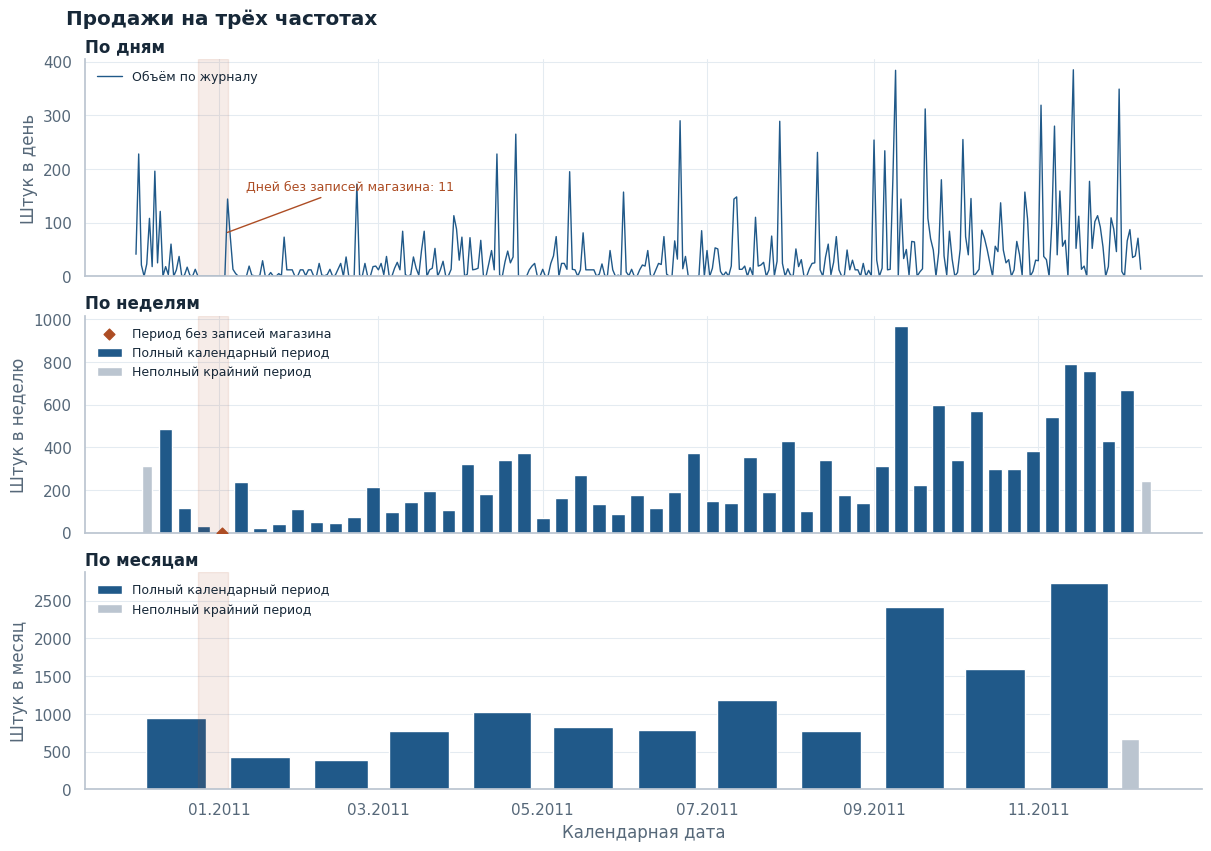

In [3]:
daily = daily_sales(rows, sales, STOCK_CODE)
weekly = aggregate_sales(daily, "W-SUN")
monthly = aggregate_sales(daily, "MS")
frequencies = {"День": "D", "Неделя": "W-SUN", "Месяц": "MS"}
all_periods = {"День": aggregate_sales(daily, "D"), "Неделя": weekly, "Месяц": monthly}

assert daily.index.equals(pd.date_range(daily.index.min(), daily.index.max(), name="date"))
assert all(t["units"].sum() == product["Quantity"].sum() for t in all_periods.values())
assert all(t["units"].notna().all() for t in all_periods.values())

statuses = pd.Series({
    "Товар продавался": daily["product_active"].sum(),
    "Магазин продавал, товар не продавался": (daily["shop_active"] & ~daily["product_active"]).sum(),
    "Нет записей о продажах магазина": daily["coverage_uncertain"].sum(),
})
display(statuses.to_frame("дней"))
gaps = contiguous_dates(daily["coverage_uncertain"])
with pd.option_context("display.max_rows", len(gaps)):
    display(gaps)
display(weekly.loc[~weekly["full_period"] | weekly["shop_days"].eq(0)], monthly.loc[~monthly["full_period"]])

plot_overview(daily, weekly, monthly, gaps.loc[gaps["дней"].idxmax()])
plt.show()

В журнале **14 528 шт. за 374 календарных дня**. Из 93 дней с нулём по товару у 24 есть продажи других товаров, у 69 нет записей о продажах магазина. В последние входят все 53 субботы и разрыв с 24 декабря по 3 января включительно. Целая неделя с окончанием 2 января лежит внутри этого разрыва. В первый день журнал начинается в 08:26, в последний заканчивается в 12:50. Полнота крайних дат неизвестна.

Для основной диагностики беру непрерывный отрезок из **48 календарных недель** с 3 января по 4 декабря 2011 г. Так остаётся регулярная сетка без целиком пустой недели и неполных краёв. По 42 неделям есть продажи магазина во все шесть обычных активных дней, ещё шесть недель имеют от четырёх до пяти таких дней.

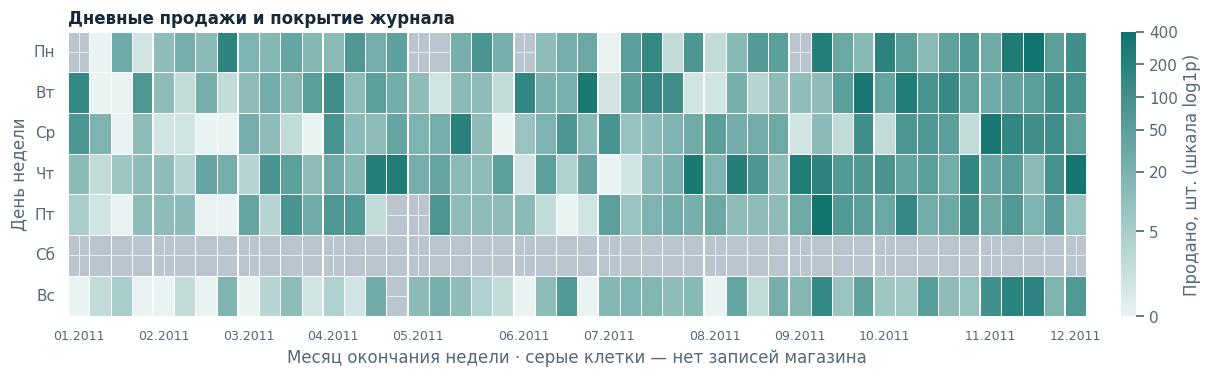

In [4]:
analysis_days = daily.loc["2011-01-03":"2011-12-04"]
analysis_weeks = weekly.loc["2011-01-09":"2011-12-04"]
y_day = analysis_days["units"]
y_week = analysis_weeks["units"]
rate = y_week / analysis_weeks["shop_days"]
assert analysis_weeks["full_period"].all() and analysis_weeks["shop_days"].gt(0).all()
assert len(y_day) == 7 * len(y_week) and y_day.sum() == y_week.sum()

matrix = weekday_sales_matrix(analysis_days)
plot_coverage(matrix)
plt.show()

Серые клетки на карте показывают дни без продаж магазина. Светлые цветные клетки могут содержать ноль по товару при наличии продаж магазина. В январе и феврале преобладают небольшие объёмы. В сентябре и ноябре крупные суммы встречаются и в нескольких разных днях одной недели.

## 3 Уровень и разброс

Для сравнения частот беру общий календарный отрезок с февраля по ноябрь. Он обходит длинный зимний разрыв и декабрьский край выгрузки. В расчёт входят только периоды, целиком попавшие в это окно. На недельной частоте поэтому исключены две пограничные недели. Коэффициент вариации — отношение стандартного отклонения к среднему.

,периодов,сумма,среднее,медиана,σ,CV,P95,пик,"нулевых, %"
День,303.0,12492.0,41.23,15.0,66.34,1.61,180.90,385.0,21.45
Неделя,42.0,12212.0,290.76,219.0,208.55,0.72,749.95,968.0,0.00
Месяц,10.0,12492.0,1249.20,923.0,771.82,0.62,2596.35,2739.0,0.00


,недель,"медиана, шт. в неделю","медиана, шт. на активный день",в среднем активных дней
date,,,,
2011Q1,12,101.5,16.92,5.92
2011Q2,13,180.0,32.20,5.54
2011Q3,13,222.0,37.00,5.92
2011Q4,10,488.0,81.33,6.00


,первая половина,вторая половина,отношение второй к первой
Штук в неделю,138.0,348.00,2.52
Штук на активный день,23.0,60.52,2.63
Штук на активный день без трёх самых крупных недель,23.0,57.17,2.49


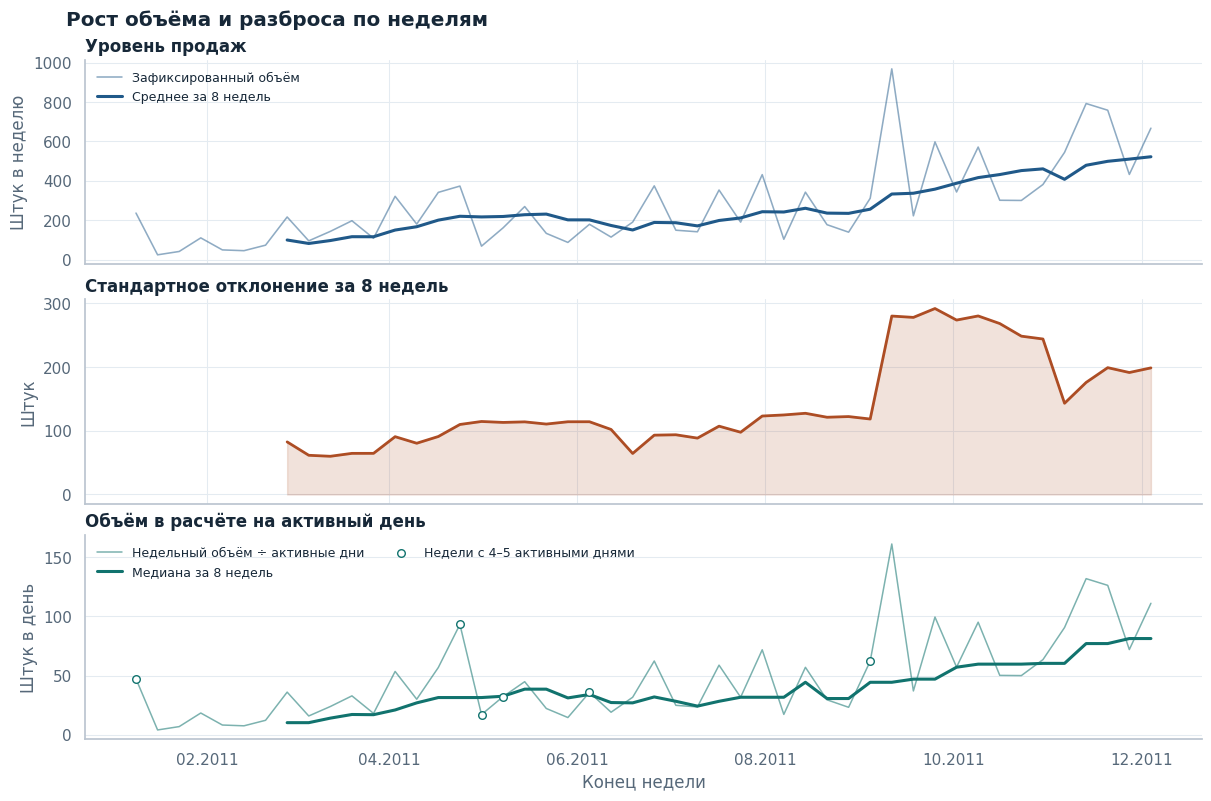

In [5]:
comparison_days = daily.loc["2011-02-01":"2011-11-30"]
comparison = {}
for label, freq in frequencies.items():
    frame = aggregate_sales(comparison_days, freq)
    comparison[label] = frame.loc[frame["full_period"], "units"]
display(pd.DataFrame({label: describe_sales(y) for label, y in comparison.items()}).T.round(2))

dynamics = analysis_weeks.assign(rate=rate)
quarter = dynamics.groupby(dynamics.index.to_period("Q")).agg(
    недель=("units", "size"), медиана_в_неделю=("units", "median"),
    медиана_за_активный_день=("rate", "median"), среднее_активных_дней=("shop_days", "mean"),
)
display(quarter.rename(columns={
    "медиана_в_неделю": "медиана, шт. в неделю",
    "медиана_за_активный_день": "медиана, шт. на активный день",
    "среднее_активных_дней": "в среднем активных дней",
}).round(2))

def compare_halves(series, first_half_end):
    halves = series.groupby(series.index > first_half_end).median()
    return pd.Series({
        "первая половина": halves.loc[False],
        "вторая половина": halves.loc[True],
        "отношение второй к первой": halves.loc[True] / halves.loc[False],
    })

comparison_halves = {
    "Штук в неделю": y_week,
    "Штук на активный день": rate,
    "Штук на активный день без трёх самых крупных недель": rate.drop(y_week.nlargest(3).index),
}
first_half_end = y_week.index[len(y_week) // 2 - 1]
display(pd.DataFrame({k: compare_halves(v, first_half_end) for k, v in comparison_halves.items()}).T.round(2))
plot_dynamics(analysis_weeks, rate)
plt.show()

Даже на общем отрезке CV снижается при агрегации с **1,61 по дням до 0,72 по неделям и 0,62 по месяцам**. Дневная медиана 15 шт. заметно ниже среднего (41,2 шт.). Недельная частота даёт более ровный ряд и больше наблюдений, чем месячная. Оценка месячного CV основана всего на десяти месяцах, а их длина различается.

Медиана недельных сумм выросла со 101,5 в I квартале до 488 шт. в наблюдаемой части IV квартала. **Рост сохраняется после поправки на число активных дней.** Объём на активный день во второй половине отрезка примерно в 2,63 раза выше по медиане, чем в первой. Если убрать три крупнейшие недели только для этой проверки, отношение остаётся около 2,49. Нормировка учитывает число активных дней, хотя не учитывает возможное изменение часов работы или наличия товара.

## 4 Пики относительно всего ряда и недавних недель

Сначала отмечаю значения выше общего порога Тьюки $Q_3 + 1.5(Q_3 - Q_1)$ на каждой частоте. Этот порог отвечает на вопрос, какие объёмы велики на всём интервале. При растущем уровне он закономерно чаще отмечает недели ближе к концу ряда.

Затем для каждой недели сравниваю её `log1p` с локальным фоном из предыдущих десяти недель. Центр — медиана, масштаб — $1.4826 \times MAD$, где $MAD$ — медиана абсолютных отклонений от медианы. Если есть хотя бы восемь наблюдений и масштаб положителен, считаю робастный z. Значения выше 3,5 отмечаю как кандидатов на разбор. В фон входят только предшествующие недели. Отдельно меняю длину окна на восемь и двенадцать недель.

,"порог, шт.",отмечено
Дни,115.38,32.0
Недели,702.62,3.0
Месяцы,2044.88,2.0


,доступно оценок,отмечено
"окно, недель",,
8,40,0
10,40,1
12,40,0


,total,invoices,largest_invoice,largest_share,global_flag,local_flag,local_z
date,,,,,,,
2011-07-31,431,14,288,0.67,False,True,3.68
2011-09-11,968,15,360,0.37,True,False,2.79
2011-11-13,792,39,253,0.32,True,False,1.78
2011-11-20,758,38,268,0.35,True,False,0.99


,total,invoices,largest_invoice,largest_share
date,,,,
2011-11-14,385,9,268,0.70
2011-09-09,384,2,360,0.94
2011-12-01,349,12,216,0.62
2011-11-02,319,5,288,0.90
2011-09-20,312,3,288,0.92


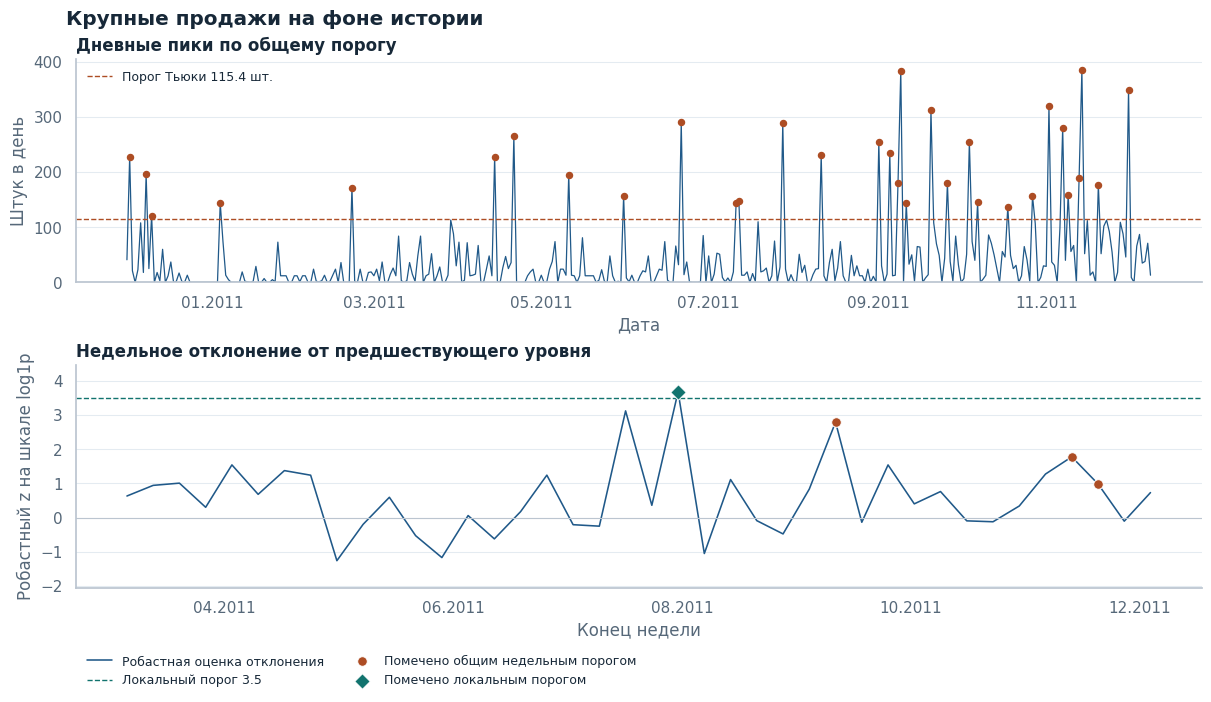

In [6]:
full_months = monthly.loc[monthly["full_period"], "units"]
samples = {"Дни": daily["units"], "Недели": y_week, "Месяцы": full_months}
global_checks = {name: upper_iqr_flags(values) for name, values in samples.items()}
display(pd.DataFrame({
    name: {"порог, шт.": bound, "отмечено": mask.sum()}
    for name, (mask, bound) in global_checks.items()
}).T.round(2))

day_flags, day_limit = global_checks["Дни"]
week_flags, _ = global_checks["Недели"]
local_checks = {n: trailing_anomalies(y_week, window=n) for n in (8, 10, 12)}
local = local_checks[10]
assert local["score"].iloc[:8].isna().all()
display(pd.DataFrame({
    n: {"доступно оценок": t["score"].notna().sum(), "отмечено": t["flag"].sum()}
    for n, t in local_checks.items()
}).T.rename_axis("окно, недель"))

review = week_flags | local["flag"]
invoice_week = peak_invoice_summary(product, y_week.index[review], freq="W-SUN")
assert invoice_week["total"].equals(y_week.loc[review].rename("total"))
display(invoice_week.assign(
    global_flag=week_flags.loc[review], local_flag=local.loc[review, "flag"],
    local_z=local.loc[review, "score"],
).round(2))
display(peak_invoice_summary(product, daily["units"].nlargest(5).index).round(2))
plot_peaks(daily["units"], day_flags, day_limit, local, week_flags)
plt.show()

Общий порог отмечает **32 дня** и **три недели**. В пике 9 сентября 360 из 384 шт. пришлись на один счёт. У дня с максимальным объёмом, 14 ноября, 385 шт. распределены по девяти счетам.

В десятинедельном окне локальный порог выделил неделю, окончившуюся **31 июля**. В ней 431 шт., из них 288 в одном счёте. Недельный максимум **968 шт.** 11 сентября выделяется по общему порогу, а его локальный z составляет 2,79. При окнах 8 и 12 недель локальных срабатываний нет. Таким образом, июльский сигнал зависит от настройки окна. Пики оставлены в ряду, поскольку счета объясняют большую часть резких скачков, а правила детекции дают разные списки. Целиком пустая неделя остаётся на обзорном графике с отметкой покрытия. Интерполяцию не применяю.

## 5 Недельный ритм

### Декомпозиция записанных объёмов

Применяю робастную аддитивную STL с периодом семь дней. Период задаётся из календаря. Проверяю его согласие с автокорреляцией, профилем дней и отдельным тестом на сопоставимых неделях. Робастная подгонка снижает влияние пиков на компоненты, сохраняя сами наблюдения.

,дневной ряд,остаток STL,первая половина,вторая половина
лаг,,,,
7,0.225,-0.013,0.218,0.164
14,0.181,-0.022,0.036,0.147
21,0.206,0.098,0.086,0.143


Сила сезонной компоненты STL: 0.177


,"медиана тренда, шт."
date,
2011Q1,11.0
2011Q2,11.6
2011Q3,26.0
2011Q4,55.9


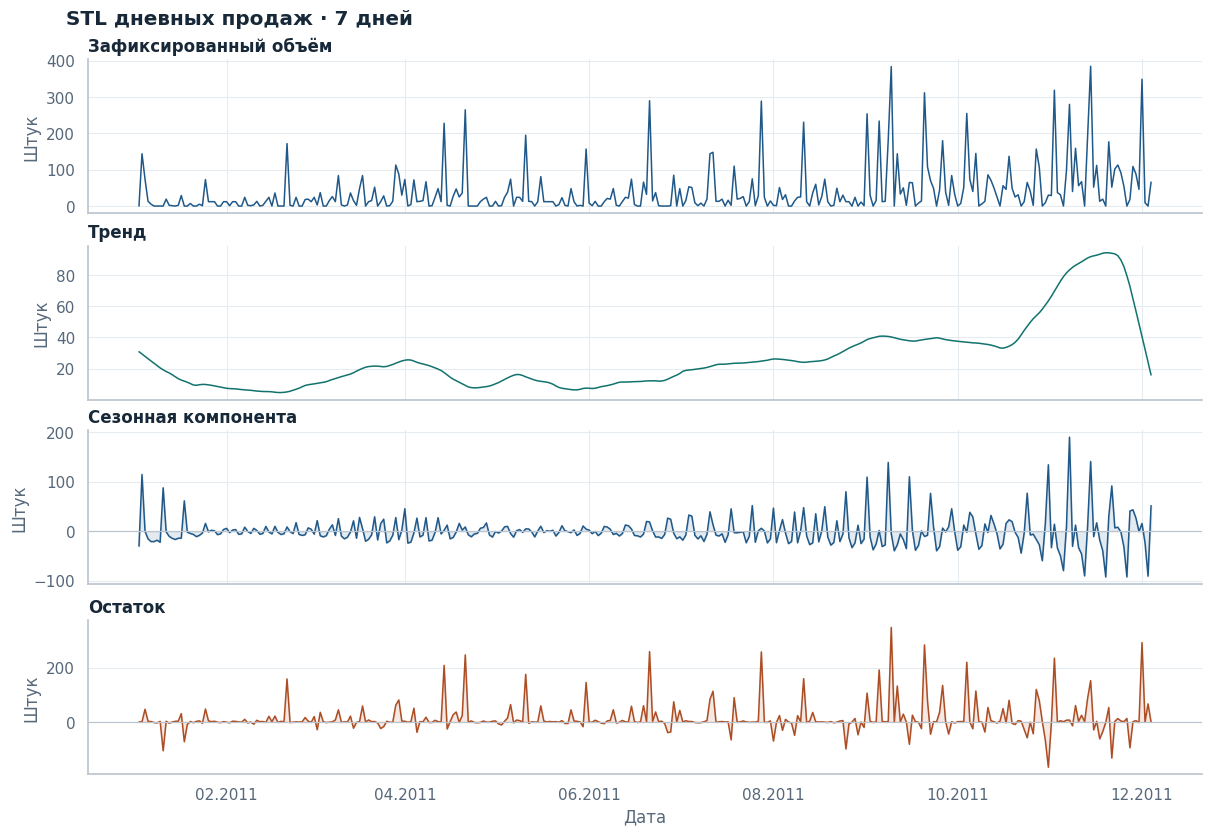

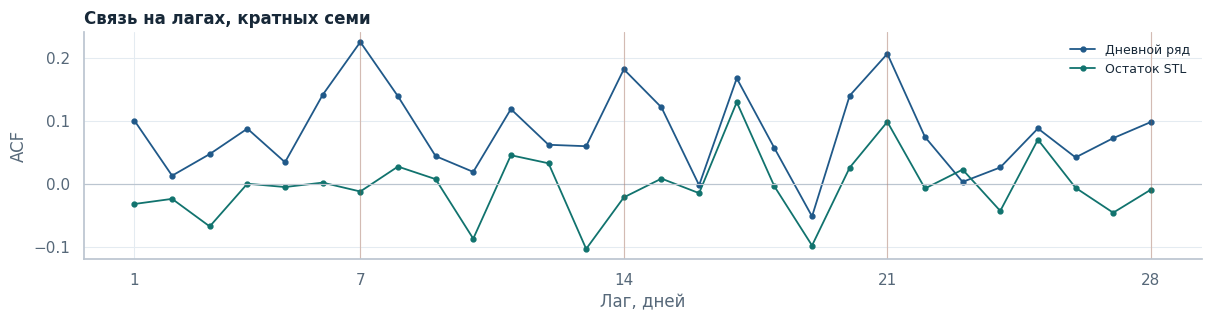

In [7]:
stl, strength = decompose(y_day, period=7)
second_half_starts = analysis_days.index[len(analysis_days) // 2]
acf_inputs = {
    "дневной ряд": y_day,
    "остаток STL": stl.resid,
    "первая половина": y_day.loc[y_day.index < second_half_starts],
    "вторая половина": y_day.loc[second_half_starts:],
}
display(pd.DataFrame({
    name: autocorrelations(y) for name, y in acf_inputs.items()
}).loc[[7, 14, 21]].round(3))
print(f"Сила сезонной компоненты STL: {strength:.3f}")
display(stl.trend.groupby(stl.trend.index.to_period("Q")).median().round(1).to_frame("медиана тренда, шт."))
plot_decomposition(y_day, stl)
plt.show()
plot_seasonal_acf(y_day, stl.resid)
plt.show()

**Тренд.** Медиана сглаженного уровня выросла с 11 шт. в день в I квартале примерно до 56 в наблюдаемой части IV квартала. Резкое снижение оценки STL у правой границы следует читать с осторожностью: там меньше соседних наблюдений для сглаживания.

**Сезонная компонента.** ACF на лагах 7, 14 и 21 равна 0,225, 0,181 и 0,206. На лаге 7 связь сохраняется в обеих половинах периода. Мера силы сезонности $\max(0, 1-\operatorname{Var}(R)/\operatorname{Var}(S+R))$ равна **0,177**, где $R$ — остаток, $S$ — сезонная компонента. Рисунок заметен, хотя сезонная компонента оставляет значительную часть изменчивости в остатке.

**Остаток.** Автокорреляции на лагах 7 и 14 после STL близки к нулю (−0,013 и −0,022). Крупные скачки сохраняются. Доступная история слишком коротка для проверки повторяющейся годовой сезонности.

### Проверка дней недели с сопоставимым покрытием

**Нулевая гипотеза** — после сравнения дней внутри одной недели их названия обменяемы, то есть устойчивой связи дня с рангом объёма нет. Беру 42 недели, где есть продажи магазина во все дни с понедельника по пятницу и в воскресенье. Субботы исключены. Сравнение рангов **внутри** недели ослабляет влияние общего роста и крупных заказов.

Для статистики Фридмана оцениваю p по 19 999 перестановкам с фиксированным seed. В первой версии меняю метки независимо в каждой неделе. Во второй меняю метки одинаково для всех недель внутри каждого четырёхнедельного календарного блока. Так сохраняю часть серийной зависимости между соседними неделями. Вторая проверка предполагает обменяемость меток на уровне блоков. Сохраняющаяся зависимость между блоками может влиять на p.

,недель,блоков,χ² Фридмана,W Кендалла,p перестановок
Независимо по неделям,42.0,42.0,18.7105,0.0891,0.0020
Общие метки внутри 4 недель,42.0,12.0,18.7105,0.0891,0.0033


,"медиана, шт.",средний ранг
Пн,29.5,3.95
Вт,25.0,3.76
Ср,19.0,3.44
Чт,33.0,4.02
Пт,19.0,3.27
Вс,12.0,2.55


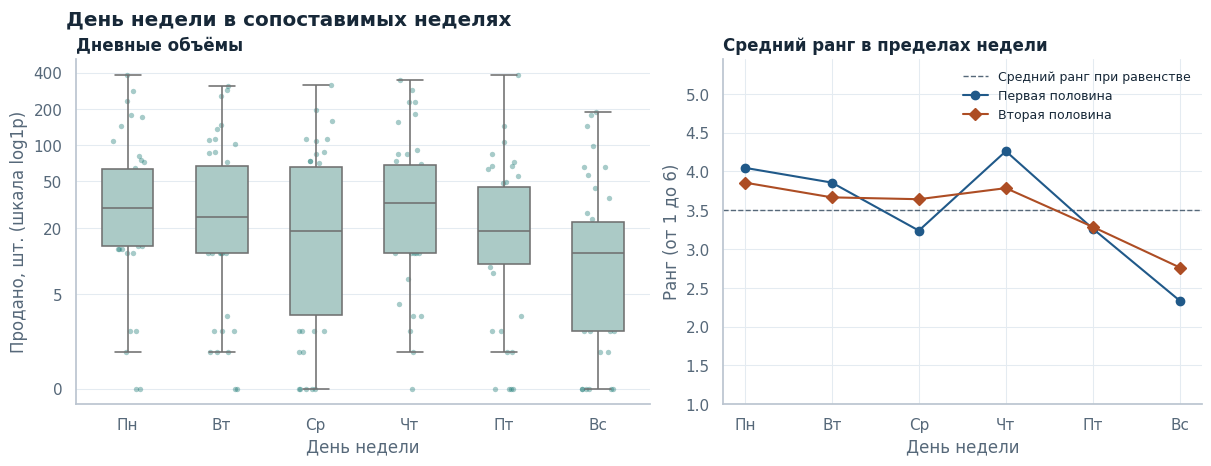

In [8]:
active = matrix[["Пн", "Вт", "Ср", "Чт", "Пт", "Вс"]].dropna()
assert len(active) == analysis_weeks["shop_days"].eq(6).sum()
permutation = pd.DataFrame({
    "Независимо по неделям": weekday_permutation_test(active),
    "Общие метки внутри 4 недель": weekday_permutation_test(active, block_weeks=4),
}).T
display(permutation.round(4))
display(pd.DataFrame({"медиана, шт.": active.median(), "средний ранг": active.rank(axis=1).mean()}).round(2))
plot_weekdays(active)
plt.show()

Получилось **p = 0,0020** при перестановках по неделям и **p = 0,0033** с четырёхнедельными блоками. Это свидетельство различий среди шести активных дней и без субботы. Размер эффекта небольшой, **W Кендалла = 0,089**. Медианы четверга и воскресенья составляют 33 и 12 шт., а разброс дней сильно перекрывается. Воскресенье ниже по среднему рангу в обеих половинах выборки. Это исследовательский результат по журналу магазина. Он не устанавливает причину различий или эффект для будущего периода.

## 6 Стационарность недельных объёмов

Использую два теста при уровне значимости 5%. У **ADF** нулевая гипотеза о единичном корне, лаги выбираются по AIC. У **KPSS** нулевая гипотеза о стационарности вокруг постоянного уровня. Знаки `<` и `>` у KPSS показывают границы табличных p-значений.

Сравниваю недельные суммы, их `log1p`, первые разности и первые разности `log1p`. Проверяю, сохраняется ли вывод при других лагах KPSS и после нормировки на дни с продажами магазина. Дополнительная проверка с линейным трендом помогает отделить задачу удаления меняющегося уровня от вопроса о единичном корне.

статистика          p  \
ряд                                           тест                          
Недельный объём                               ADF       -2.029     0.2741   
                                              KPSS       0.851     < 0.01   
log1p объёма                                  ADF       -1.767     0.3972   
                                              KPSS       0.864     < 0.01   
Первая разность объёма                        ADF       -6.353   2.59e-08   
                                              KPSS       0.190     > 0.10   
Первая разность log1p                         ADF       -6.677   4.44e-09   
                                              KPSS       0.323     > 0.10   
Объём на активный день                        ADF       -2.197     0.2073   
                                              KPSS       0.815     < 0.01   
Первая разность log1p объёма на активный день ADF      -10.277  3.874e-18   
                                              KPSS       0.325     > 0.10   

                                                    лаги  H₀ отклонена при 5%  
ряд                                           тест                             
Недельный объём                               ADF      1                False  
                                              KPSS     4                 True  
log1p объёма                                  ADF      2                False  
                                              KPSS     4                 True  
Первая разность объёма                        ADF      2                 True  
                                              KPSS     8                False  
Первая разность log1p                         ADF      2                 True  
                                              KPSS    21                False  
Объём на активный день                        ADF      1                False  
                                              KPSS     4                 True  
Первая разность log1p объёма на активный день ADF      1                 True  
                                              KPSS    22                False

,Недельный объём,Первая разность log1p
лаги KPSS,,
2,< 0.01,> 0.10
4,< 0.01,> 0.10
8,0.02328,> 0.10
10,0.03686,> 0.10


статистика          p  лаги  \
ряд          тест с линейным трендом                                
объём        ADF                          -7.105  8.178e-09     0   
             KPSS                          0.146    0.04975     2   
log1p объёма ADF                          -7.566  7.182e-10     0   
             KPSS                          0.080     > 0.10     2   

                                      H₀ отклонена при 5%  
ряд          тест с линейным трендом                       
объём        ADF                                     True  
             KPSS                                    True  
log1p объёма ADF                                     True  
             KPSS                                   False

,σ первой половины,σ второй половины,ACF на лаге 1
Недельный объём,97.732,229.935,0.414
log1p объёма,0.711,0.606,0.489
Первая разность объёма,125.637,295.112,-0.569
Первая разность log1p,0.879,0.778,-0.461


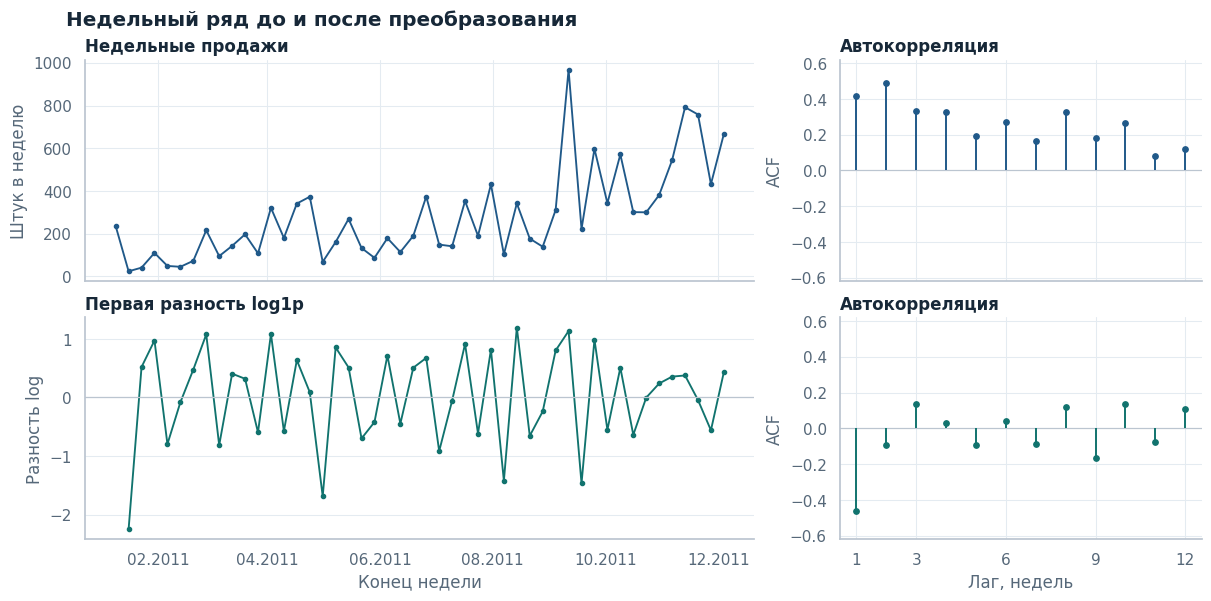

In [9]:
log_week = np.log1p(y_week)
diff_log = log_week.diff().dropna()
variants = {
    "Недельный объём": y_week, "log1p объёма": log_week,
    "Первая разность объёма": y_week.diff().dropna(), "Первая разность log1p": diff_log,
    "Объём на активный день": rate, "Первая разность log1p объёма на активный день": np.log1p(rate).diff().dropna(),
}
test_results = pd.concat(
    {name: stationarity_tests(series) for name, series in variants.items()},
    names=["ряд", "тест"],
)
display(test_results.round(3))

bandwidth = pd.DataFrame({
    label: {
        lag: stationarity_tests(series, kpss_lags=lag).loc["KPSS", "p"]
        for lag in (2, 4, 8, 10)
    }
    for label, series in {"Недельный объём": y_week, "Первая разность log1p": diff_log}.items()
})
display(bandwidth.rename_axis("лаги KPSS"))
display(pd.concat(
    {"объём": stationarity_tests(y_week, regression="ct"),
     "log1p объёма": stationarity_tests(log_week, regression="ct")},
    names=["ряд", "тест с линейным трендом"],
).round(3))

dispersion = {}
for name, series in list(variants.items())[:4]:
    midpoint = len(series) // 2
    dispersion[name] = {
        "σ первой половины": series.iloc[:midpoint].std(),
        "σ второй половины": series.iloc[midpoint:].std(),
        "ACF на лаге 1": autocorrelations(series, nlags=1).loc[1],
    }
display(pd.DataFrame(dispersion).T.round(3))
plot_transformation(y_week, diff_log)
plt.show()

Для недельных сумм ADF даёт **p = 0,2741**, KPSS — **p < 0,01**. Вместе с ростом медианы это указывает на отсутствие стационарности относительно постоянного уровня. На одном `log1p` вывод сохраняется, хотя разброс двух половин становится ближе.

У первой разности `log1p` ADF даёт **p ≈ 4,44 × 10⁻⁹**, KPSS — **p > 0,10**. Стандартные отклонения половин равны 0,879 и 0,778. В разностях объёма без логарифма разница заметно больше (126 и 295 шт.). Вердикт KPSS сохраняется при лагах 2, 4, 8 и 10, а нормировка на число активных дней даёт то же качественное различие до и после преобразования.

Для `log1p` дополнительная спецификация с трендом отвергает единичный корень по ADF и согласуется со стационарностью вокруг линейного тренда по KPSS. У первых логарифмических разностей ACF на первом лаге около −0,46. Поэтому для будущей модели оставляю две обоснованные формы: **разности `log1p`** для модели постоянного уровня и **`log1p` с явным трендом** для проверки, нужен ли шаг дифференцирования. С 48 неделями различать эти варианты лучше на последовательных отложенных интервалах, а не по одному p-значению.

## 7 Выводы

Для недельного горизонта использовал бы недельные суммы с отдельной отметкой о покрытии. Пики сохраняю. Июльская неделя показывает, почему большой объём стоит сравнивать и со всем рядом, и с недавней историей. Рост уровня заметен даже в расчёте на активный день и после исключения трёх крупнейших недель в проверке чувствительности.

Дневной недельный ритм частично связан с субботами. Среди шести активных дней тоже есть небольшие устойчивые различия, но после недельной агрегации отдельный семидневный компонент уже не нужен. У недельных разностей `log1p` разброс первой и второй половин ближе, чем у разностей в штуках. В дальнейшей проверке сравнил бы её с простым прогнозом по последней неделе и с моделью явного тренда, рассчитывая фон и параметры только по доступной на тот момент истории.

## Источники

- Daqing Chen (2015). [Online Retail](https://doi.org/10.24432/C5BW33). UCI Machine Learning Repository, CC BY 4.0.
- Статистика Фридмана с поправкой на одинаковые ранги. [SciPy 1.12](https://docs.scipy.org/doc/scipy-1.12.0/reference/generated/scipy.stats.friedmanchisquare.html).
- Мера силы сезонности. [Hyndman и Athanasopoulos, Forecasting: Principles and Practice](https://otexts.com/fpp3/stlfeatures.html).
- Спецификации тестов. [ADF](https://www.statsmodels.org/stable/generated/statsmodels.tsa.stattools.adfuller.html), [KPSS](https://www.statsmodels.org/stable/generated/statsmodels.tsa.stattools.kpss.html).